# Feature-space view of predicted classes (t-SNE)

Collects the image features each method actually classified with and shows a t-SNE of the samples tied to chosen classes.
- **NoAdapt features** are the zero-shot CLIP features.
- **Ramen features** are the features *after* Ramen's per-sample adaptation, i.e. the ones its prediction came from.

Showing both side by side reveals whether wrong predictions (e.g. → *tractor*) come from features that were already mixed up, or from features that adaptation moved into the deer region.

Everything you'd want to change is in the **Settings** cell.

In [5]:
%load_ext autoreload
%autoreload 2

import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '1')  # pick a free GPU; must be set before torch is imported

from ramen_analysis import make_experiment

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Settings

In [6]:
# --- experiment (must match a run you want to analyse; results are cached in results/) ---
DATASET      = 'CIFAR100C'   # 'CIFAR10C' | 'CIFAR100C'
MODEL        = None          # None = dataset default (CIFAR10C: clip_vitbase32, CIFAR100C: clip_vitbase16)
TTA_MODE     = 'mixed'       # 'mixed' | 'single'
N_PER_DOMAIN = None          # None = whole dataset; e.g. 1000 for a quick run

# --- what to plot ---
CLASSES       = ['oak_tree']  # Ramen-induced over-prediction on full data: 1206 -> 2557 predictions (true 1500)
SELECT        = 'pred'       # 'pred' predicted as CLASSES | 'true' labelled CLASSES | 'either' | 'wrong' (wrongly predicted as CLASSES)
SELECT_BY     = 'Ramen'      # whose predictions define the selection: 'Ramen' | 'NoAdapt'
COLOR_BY      = 'label'      # 'label' (true class) | 'pred' | 'domain' | 'outcome' (fixed/broken vs NoAdapt) | 'correct'
FEATURES_FROM = None         # None = both side by side | 'Ramen' | 'NoAdapt'
DOMAINS       = None         # None = all corruptions, or e.g. ['gaussian_noise', 'shot_noise']
MAX_POINTS    = 3000         # random subsample above this (t-SNE gets slow past ~10k points)
PERPLEXITY    = 30

## Run (or load) both methods with feature capture
This re-runs a method if its cached results were saved without features (e.g. by the other notebooks), so expect roughly the same time as a normal evaluation the first time.

In [7]:
exp = make_experiment(DATASET, model=MODEL, tta_mode=TTA_MODE, n_per_domain=N_PER_DOMAIN).load()
exp.evaluate(capture_features=True)

CIFAR100C: 15 corruptions x 10000 images, 100 classes, model=clip_vitbase16, mode=mixed
NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR100C_clip_vitbase16_mixed_nall_bs100_s0_NoAdapt.pkl
Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR100C_clip_vitbase16_mixed_nall_bs100_s0_Ramen.pkl


,NoAdapt,Ramen,delta
gaussian_noise,22.83,30.37,7.54
shot_noise,24.42,31.98,7.56
impulse_noise,29.58,42.94,13.36
defocus_blur,43.56,52.60,9.04
glass_blur,20.16,28.95,8.79
motion_blur,43.60,52.38,8.78
zoom_blur,48.64,55.74,7.10
snow,48.91,55.30,6.39
frost,50.48,54.40,3.92
fog,41.77,52.84,11.07


## What gets absorbed into the class?
True labels of all samples each method predicts as `CLASSES[0]`.

In [8]:
exp.pred_composition(CLASSES[0])

,NoAdapt,Ramen
label,,
oak_tree,781,882
maple_tree,475,509
willow_tree,232,329
pine_tree,281,293
palm_tree,137,153
...,...,...
motorcycle,1,1
poppy,2,1
orange,6,1


## t-SNE
Colour is set by `COLOR_BY`; marker shows whether `SELECT_BY` got the sample right (o) or wrong (x). Each panel is a separate t-SNE run on the same samples, so compare which points sit together, not absolute positions.

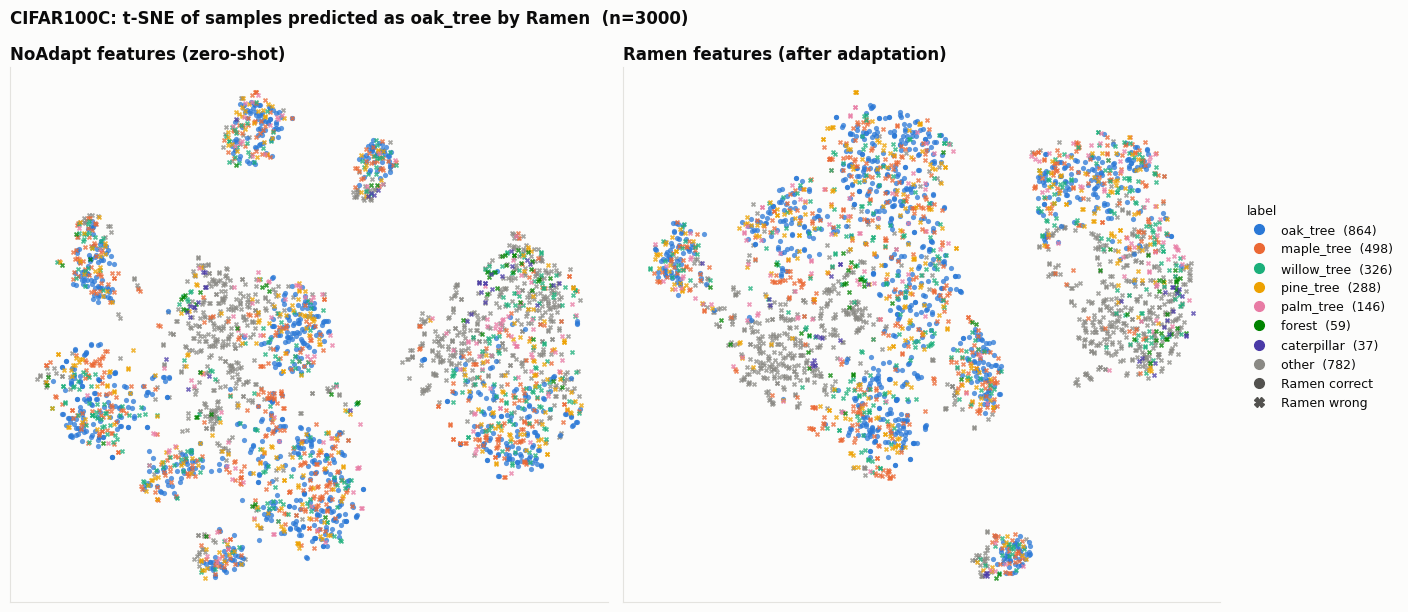

In [9]:
fig, panels = exp.plot_tsne(CLASSES, select=SELECT, algo=SELECT_BY, features_from=FEATURES_FROM, color_by=COLOR_BY,
                            domains=DOMAINS, max_points=MAX_POINTS, perplexity=PERPLEXITY)

## Variations
Only the errors (samples wrongly pulled into the class), coloured by corruption: do certain corruptions drive the collapse?

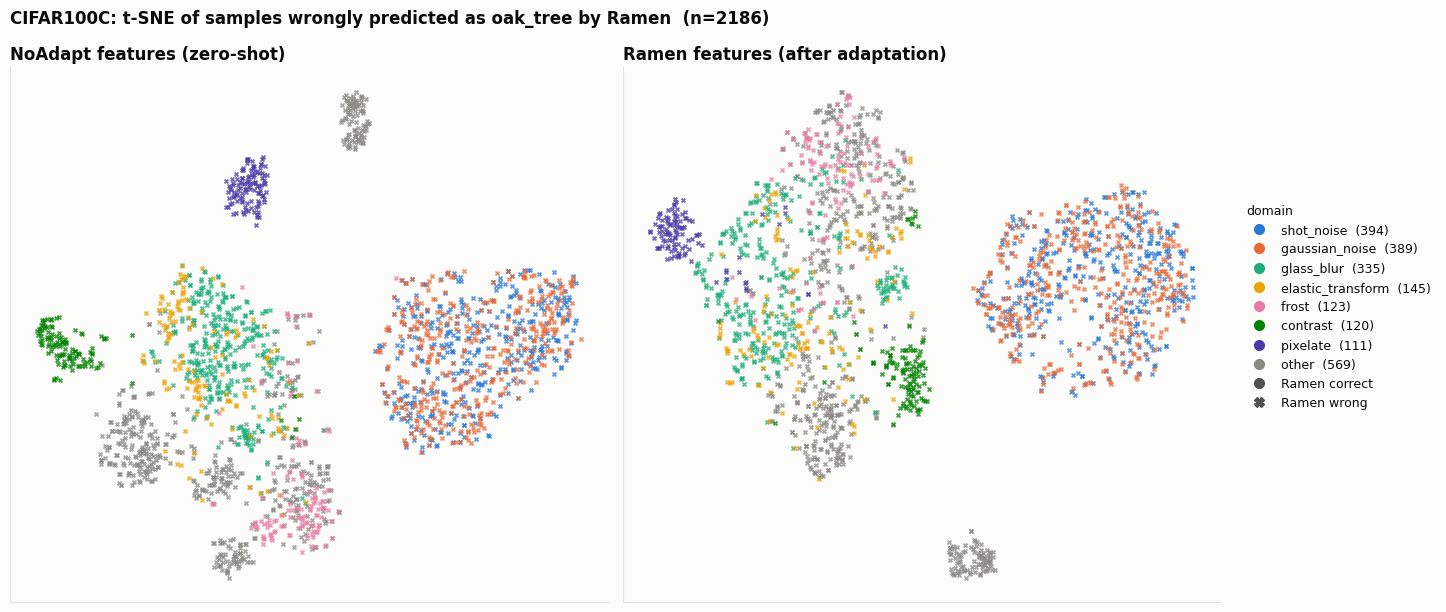

In [10]:
exp.plot_tsne(CLASSES, select='wrong', color_by='domain');

Coloured by flip outcome vs NoAdapt. Red = Ramen broke a correct zero-shot prediction.

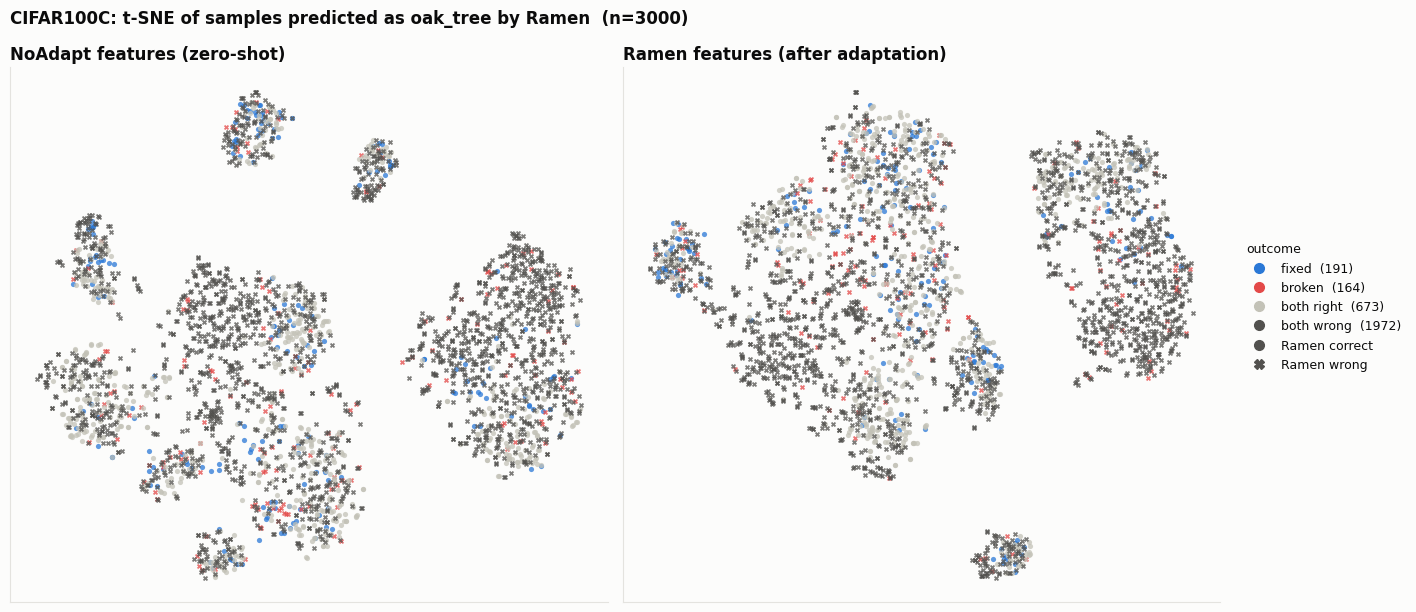

In [11]:
exp.plot_tsne(CLASSES, select='pred', color_by='outcome');

The reverse view: where do samples *truly* of the class end up, coloured by what Ramen predicted?

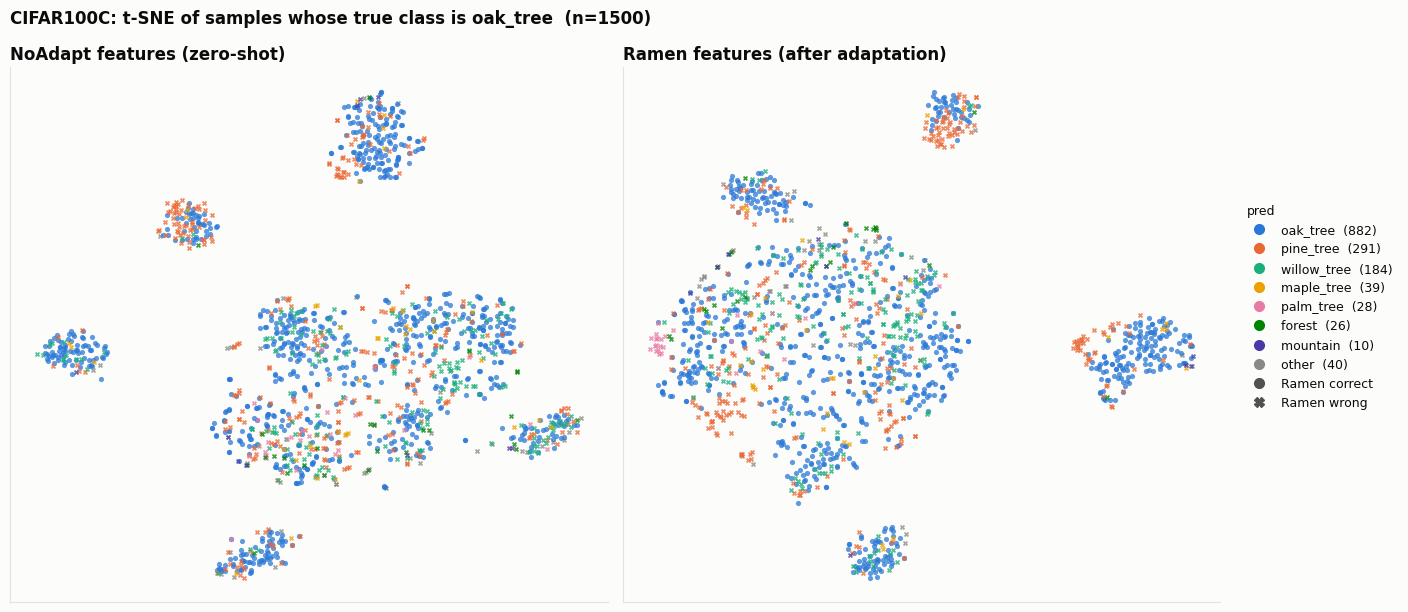

In [12]:
exp.plot_tsne(CLASSES, select='true', color_by='pred');

Loop over several classes, e.g. the ones Ramen over-predicts most (see `plot_prediction_bias` in the dataset notebooks).

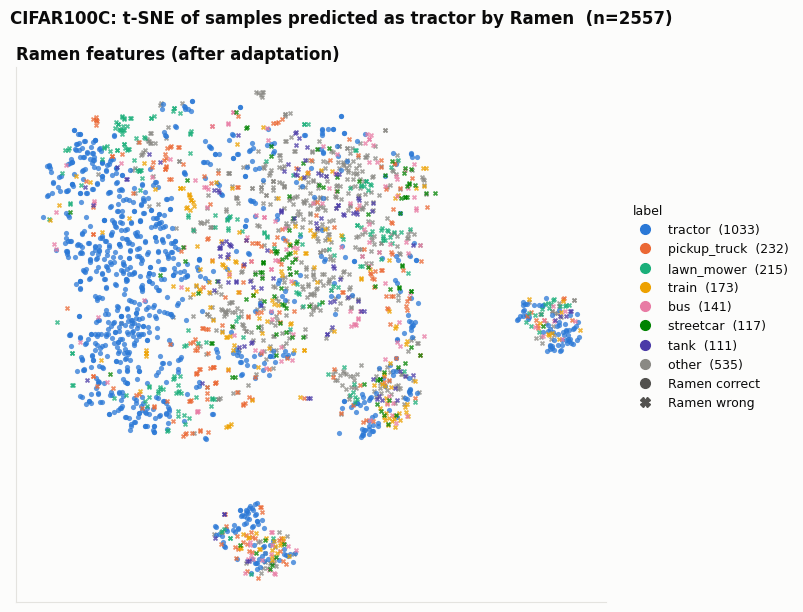

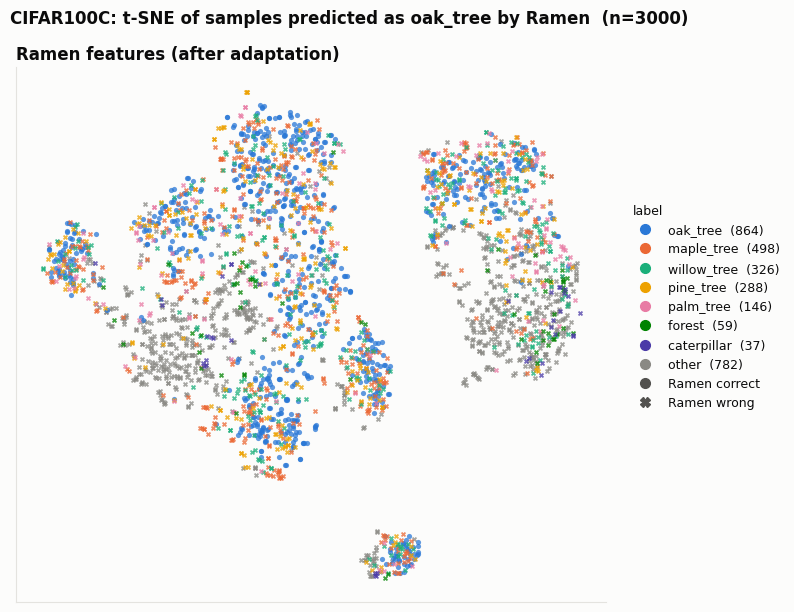

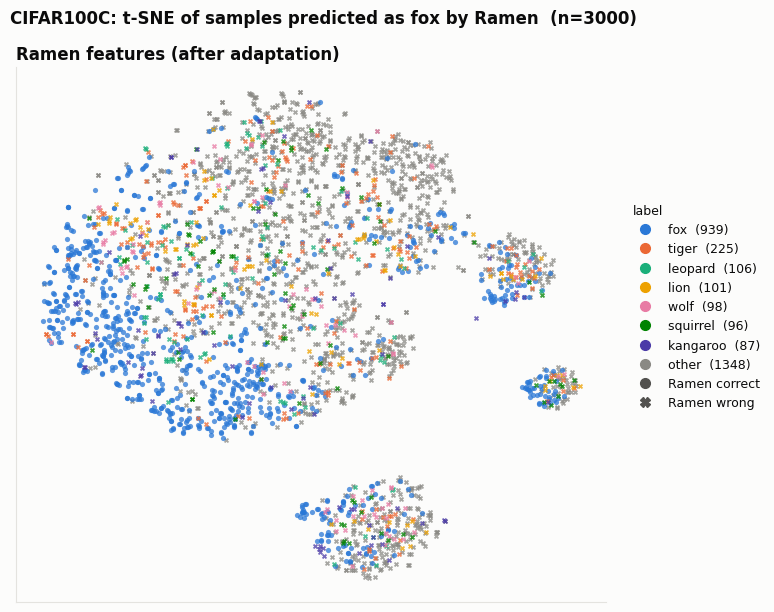

In [13]:
for cls in ['tractor', 'oak_tree', 'fox']:   # most over-predicted classes by Ramen on full data
    exp.plot_tsne(cls, select='pred', color_by='label', features_from='Ramen')

## Use the coordinates yourself
`plot_tsne` returns one DataFrame per panel with t-SNE `x`, `y` and every per-sample column (true/pred names, domain, confidence, outcome, ...).

In [14]:
panels[-1][['x', 'y', 'true_name', 'pred_name', 'domain', 'conf', 'outcome']].head()

,x,y,true_name,pred_name,domain,conf,outcome
20283,44.351845,30.567850,oak_tree,oak_tree,shot_noise,0.562775,both right
142035,54.873550,28.561968,palm_tree,oak_tree,shot_noise,0.782092,both wrong
87732,-51.075130,-11.062853,forest,oak_tree,elastic_transform,0.282896,both wrong
47842,47.640461,5.485659,dinosaur,oak_tree,shot_noise,0.276686,both wrong
64415,-27.020212,9.591280,castle,oak_tree,glass_blur,0.285389,both wrong
